# Fine-tuning results: experiments A, B and C (iTransformer)

This notebook computes all the results of the fine-tuning experiments for ONE transfer
direction (source greenhouse -> destination greenhouse), chosen in the configuration cell:

- **Experiment A**: fine-tuning convergence curve (epochs needed).
- **Experiment B**: learning curve (performance vs amount of fine-tuning data).
- **Experiment C**: comparison between same greenhouse, zero-shot transfer and fine-tuning.

It only READS the results already generated by the experiment scripts (CSV for A and B,
JSON for C). It must be run from the `./metrics` directory at the project root. Figures are
only displayed in the notebook, they are not saved to disk.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.dpi"] = 110

## 1. Configuration

Change `SOURCE_GREENHOUSE` / `DESTINATION_GREENHOUSE` to switch the transfer direction
(`"alava"` -> `"cartagena"` or `"cartagena"` -> `"alava"`). Every path and label in the
notebook is derived from these two variables.

In [2]:
SOURCE_GREENHOUSE = "cartagena"
DESTINATION_GREENHOUSE = "alava"

GREENHOUSE_LABELS = {
    "alava": "Álava",
    "cartagena": "Cartagena",
}
source_label = GREENHOUSE_LABELS[SOURCE_GREENHOUSE]
destination_label = GREENHOUSE_LABELS[DESTINATION_GREENHOUSE]

# The notebook runs from ./metrics, so the project root is one level up.
PROJECT_ROOT = Path("..")
RESULTS_DIR = PROJECT_ROOT / "results" / "finetuning" / f"{SOURCE_GREENHOUSE}_to_{DESTINATION_GREENHOUSE}"
CSV_DIR = RESULTS_DIR / "csv"

# Folder with the experiment C JSON files for each target
TARGET_DIRS = {
    "DB_TEMP_INT": RESULTS_DIR / "temperature",
    "REL_HUM_INT": RESULTS_DIR / "rel_humidity",
}

UNITS = {
    "DB_TEMP_INT": "°C",
    "REL_HUM_INT": "%RH",
}

print(f"Direction: {source_label} -> {destination_label}")
print(f"Results folder: {RESULTS_DIR.resolve()}")

Direction: Cartagena -> Álava
Results folder: C:\Users\jclps\Documents\DL-Study-for-Indoor-Climate-Prediction-and-Greenhouse-Generalization-in-Smart-Greenhouses\results\finetuning\cartagena_to_alava


## 2. Plot style

`FIGSIZE=(9, 5.5)`, axis labels at size 16, ticks/legend at size 15/10 and a soft dashed grid.
`apply_style()` is called at the end of every plot so they are all consistent.

In [3]:
FIGSIZE = (9, 5.5)
FS_AXES = 16
FS_TICKS = 15


def apply_style(ax, title=None, xlabel=None, ylabel=None, legend_title=None,
                fs_axes=FS_AXES, fs_ticks=FS_TICKS):
    # Titles are intentionally not drawn (they go in the figure caption).
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=fs_axes, labelpad=14)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=fs_axes, labelpad=14)
    ax.tick_params(axis="both", labelsize=fs_ticks)
    ax.grid(True, linestyle="--", alpha=0.3)
    handles, _ = ax.get_legend_handles_labels()
    if handles:
        ax.legend(title=legend_title, fontsize=10)
    plt.tight_layout()

## 3. Metric used in the plots

Plots B.1, C.2 and the single-metric plot in C.4 use the `METRIC` variable in this cell.
Available options: `rmse`, `mae`, `mse`, `r2`, `mape`. All of them are in actual units
(degrees, %RH...), not in the normalized scale.

Mind the direction: for `rmse`, `mae`, `mse` and `mape` **lower is better**; for `r2`
**higher is better** (the closer to 1).

In [4]:
METRIC = "mae"  # <-- change here: "rmse", "mae", "mse", "r2", "mape"

METRICS = ["r2", "mse", "rmse", "mae", "mape"]
METRIC_LABELS = {
    "rmse": "RMSE",
    "mae": "MAE",
    "mse": "MSE",
    "r2": "R\u00b2",
    "mape": "MAPE (%)",
}
metric_label = METRIC_LABELS.get(METRIC, METRIC.upper())
print(f"Using metric: {METRIC} ({metric_label})")


def metric_axis_label(metric, target):
    # Axis label for a metric with the right unit for the target.
    unit = UNITS.get(target, "")
    if metric == "r2":
        return "R\u00b2"                          # dimensionless
    if metric == "mape":
        return "MAPE (%)"                          # already a percentage
    if metric == "mse":
        return f"MSE ({unit}\u00b2)" if unit else "MSE"   # squared unit
    return f"{metric.upper()} ({unit})" if unit else metric.upper()  # rmse, mae

Using metric: mae (MAE)


## 4. Experiment A - Convergence curve

### Load the CSV

In [5]:
df_hist = pd.read_csv(CSV_DIR / "experiment_A_history.csv")

print("Experiment A - history:", df_hist.shape, "| seeds:", sorted(df_hist["seed"].unique().tolist()))
df_hist.head()

Experiment A - history: (150, 5) | seeds: [0]


,seed,epoch,train_loss,val_loss,estimated_convergence_epoch
0,0,1,0.007,0.006,15
1,0,2,0.007,0.006,15
2,0,3,0.006,0.006,15
3,0,4,0.006,0.006,15
4,0,5,0.006,0.006,15


### A.1 - All curves overlaid (one line per seed)

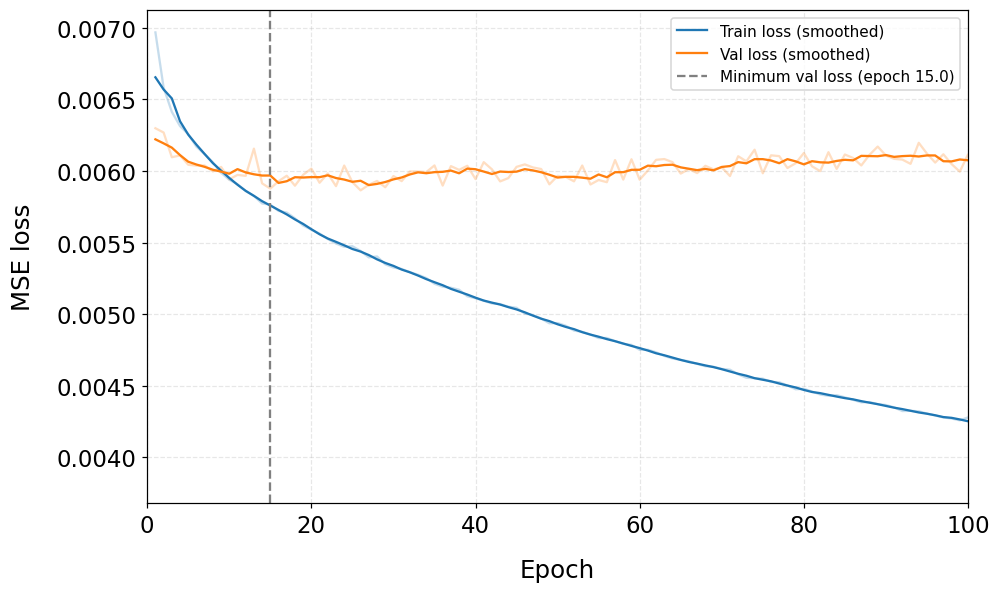

In [6]:
SMOOTHING_WINDOW = 5   # moving average size, in epochs
EPOCH_MIN = 0          # first epoch to show (None = from the start)
EPOCH_MAX = 100        # last epoch to show (None = until the end)

fig, ax = plt.subplots(figsize=FIGSIZE)

for seed, g in df_hist.groupby("seed"):
    g = g.sort_values("epoch")
    train_smooth = g["train_loss"].rolling(SMOOTHING_WINDOW, center=True, min_periods=1).mean()
    val_smooth = g["val_loss"].rolling(SMOOTHING_WINDOW, center=True, min_periods=1).mean()

    # Raw curves, semi-transparent in the background
    ax.plot(g["epoch"], g["train_loss"], color="tab:blue", alpha=0.25)
    ax.plot(g["epoch"], g["val_loss"], color="tab:orange", alpha=0.25)

    # Smoothed curves, solid on top
    ax.plot(g["epoch"], train_smooth, color="tab:blue",
            label="Train loss (smoothed)" if seed == df_hist["seed"].min() else None)
    ax.plot(g["epoch"], val_smooth, color="tab:orange",
            label="Val loss (smoothed)" if seed == df_hist["seed"].min() else None)

mean_convergence_epoch = df_hist.groupby("seed")["estimated_convergence_epoch"].first().mean()
ax.axvline(mean_convergence_epoch, color="gray", linestyle="--",
           label=f"Minimum val loss (epoch {mean_convergence_epoch:.1f})")

apply_style(ax, title=f"Fine-tuning {source_label} -> {destination_label}: convergence curve (smoothed)",
            xlabel="Epoch", ylabel="MSE loss")
ax.set_xlim(EPOCH_MIN, EPOCH_MAX)
plt.show()

## 5. Experiment B - Learning curve (amount of fine-tuning data)

### Load the CSV

In [7]:
df_b_raw = pd.read_csv(CSV_DIR / "experiment_B_raw.csv")
df_b_agg = pd.read_csv(CSV_DIR / "experiment_B_aggregated.csv")

print("Experiment B - raw:", df_b_raw.shape, "| finetune_days:", sorted(df_b_raw["finetune_days"].unique().tolist()))
print("Experiment B - aggregated:", df_b_agg.shape)

metric_columns_b = [c for c in df_b_raw.columns if c not in (
    "finetune_days", "n_train_sequences", "seed", "best_val_epoch", "epochs_run", "early_stopped"
)]
targets_b = sorted(set(c.rsplit("_", 1)[0] for c in metric_columns_b if c.endswith("_rmse")))
print("Targets detected in experiment B:", targets_b)
df_b_agg

Experiment B - raw: (138, 20) | finetune_days: [7, 14, 21, 28, 35, 42, 49, 56, 63, 70, 77, 84, 91, 98, 105, 112, 119, 126, 133, 140, 147, 154, 161, 168, 175, 182, 189, 196, 203, 210, 217, 224, 231, 238, 245, 252, 259, 266, 273, 280, 287, 294, 301, 308, 315, 322]
Experiment B - aggregated: (46, 32)
Targets detected in experiment B: ['DB_TEMP_INT', 'REL_HUM_INT']


,finetune_days,n_train_sequences,best_val_epoch_mean,best_val_epoch_std,DB_TEMP_INT_r2_mean,DB_TEMP_INT_r2_std,DB_TEMP_INT_mse_mean,DB_TEMP_INT_mse_std,DB_TEMP_INT_rmse_mean,DB_TEMP_INT_rmse_std,DB_TEMP_INT_mae_mean,DB_TEMP_INT_mae_std,DB_TEMP_INT_mape_mean,DB_TEMP_INT_mape_std,DB_TEMP_INT_relative_error_mean,DB_TEMP_INT_relative_error_std,DB_TEMP_INT_relative_error_abs_mean,DB_TEMP_INT_relative_error_abs_std,REL_HUM_INT_r2_mean,REL_HUM_INT_r2_std,REL_HUM_INT_mse_mean,REL_HUM_INT_mse_std,REL_HUM_INT_rmse_mean,REL_HUM_INT_rmse_std,REL_HUM_INT_mae_mean,REL_HUM_INT_mae_std,REL_HUM_INT_mape_mean,REL_HUM_INT_mape_std,REL_HUM_INT_relative_error_mean,REL_HUM_INT_relative_error_std,REL_HUM_INT_relative_error_abs_mean,REL_HUM_INT_relative_error_abs_std
0,7,553.000,1.000,0.000,0.778,0.001,12.131,0.060,3.483,0.009,2.070,0.022,9.677,0.205,0.007,0.012,0.097,0.002,0.720,0.008,83.987,2.360,9.164,0.128,6.520,0.098,16.216,0.313,0.092,0.009,0.162,0.003
1,14,"1,149.000",1.000,0.000,0.782,0.002,11.889,0.094,3.448,0.014,2.045,0.024,9.614,0.158,0.011,0.006,0.096,0.002,0.728,0.001,81.558,0.300,9.031,0.017,6.460,0.009,15.929,0.013,0.083,0.002,0.159,0.000
2,21,"1,778.000",1.000,0.000,0.787,0.002,11.647,0.110,3.413,0.016,2.013,0.020,9.448,0.144,0.007,0.008,0.094,0.001,0.733,0.000,80.021,0.035,8.945,0.002,6.405,0.004,15.684,0.043,0.079,0.003,0.157,0.000
3,28,"2,368.000",1.000,0.000,0.788,0.002,11.545,0.087,3.398,0.013,2.002,0.013,9.369,0.048,-0.001,0.008,0.094,0.000,0.735,0.004,79.333,1.225,8.907,0.069,6.366,0.065,15.626,0.194,0.079,0.006,0.156,0.002
4,35,"3,003.000",1.000,0.000,0.787,0.002,11.598,0.105,3.406,0.015,1.981,0.003,9.210,0.033,-0.004,0.003,0.092,0.000,0.735,0.001,79.311,0.329,8.906,0.018,6.326,0.010,15.667,0.048,0.086,0.003,0.157,0.000
5,42,"3,587.000",1.000,0.000,0.786,0.002,11.691,0.132,3.419,0.019,1.995,0.021,9.300,0.124,0.002,0.004,0.093,0.001,0.731,0.004,80.455,1.176,8.970,0.066,6.365,0.041,15.740,0.099,0.087,0.002,0.157,0.001
6,49,"4,228.000",2.333,0.577,0.784,0.001,11.796,0.058,3.435,0.008,2.006,0.015,9.374,0.091,0.005,0.005,0.094,0.001,0.733,0.003,79.924,0.844,8.940,0.047,6.328,0.025,15.607,0.097,0.087,0.004,0.156,0.001
7,56,"4,809.000",1.667,1.155,0.786,0.001,11.672,0.058,3.416,0.008,1.992,0.008,9.289,0.050,0.002,0.003,0.093,0.001,0.734,0.005,79.616,1.433,8.923,0.080,6.324,0.061,15.666,0.222,0.088,0.002,0.157,0.002
8,63,"5,453.000",1.667,0.577,0.785,0.001,11.748,0.076,3.428,0.011,1.990,0.009,9.267,0.053,-0.000,0.003,0.093,0.001,0.733,0.002,80.096,0.572,8.950,0.032,6.368,0.026,15.726,0.027,0.089,0.000,0.157,0.000
9,70,"6,033.000",1.667,0.577,0.786,0.002,11.657,0.088,3.414,0.013,1.981,0.010,9.222,0.056,0.001,0.003,0.092,0.001,0.734,0.003,79.725,1.027,8.929,0.058,6.358,0.049,15.716,0.162,0.091,0.004,0.157,0.002


### B.1 - Performance vs amount of fine-tuning data

Uses the metric chosen in `METRIC`.

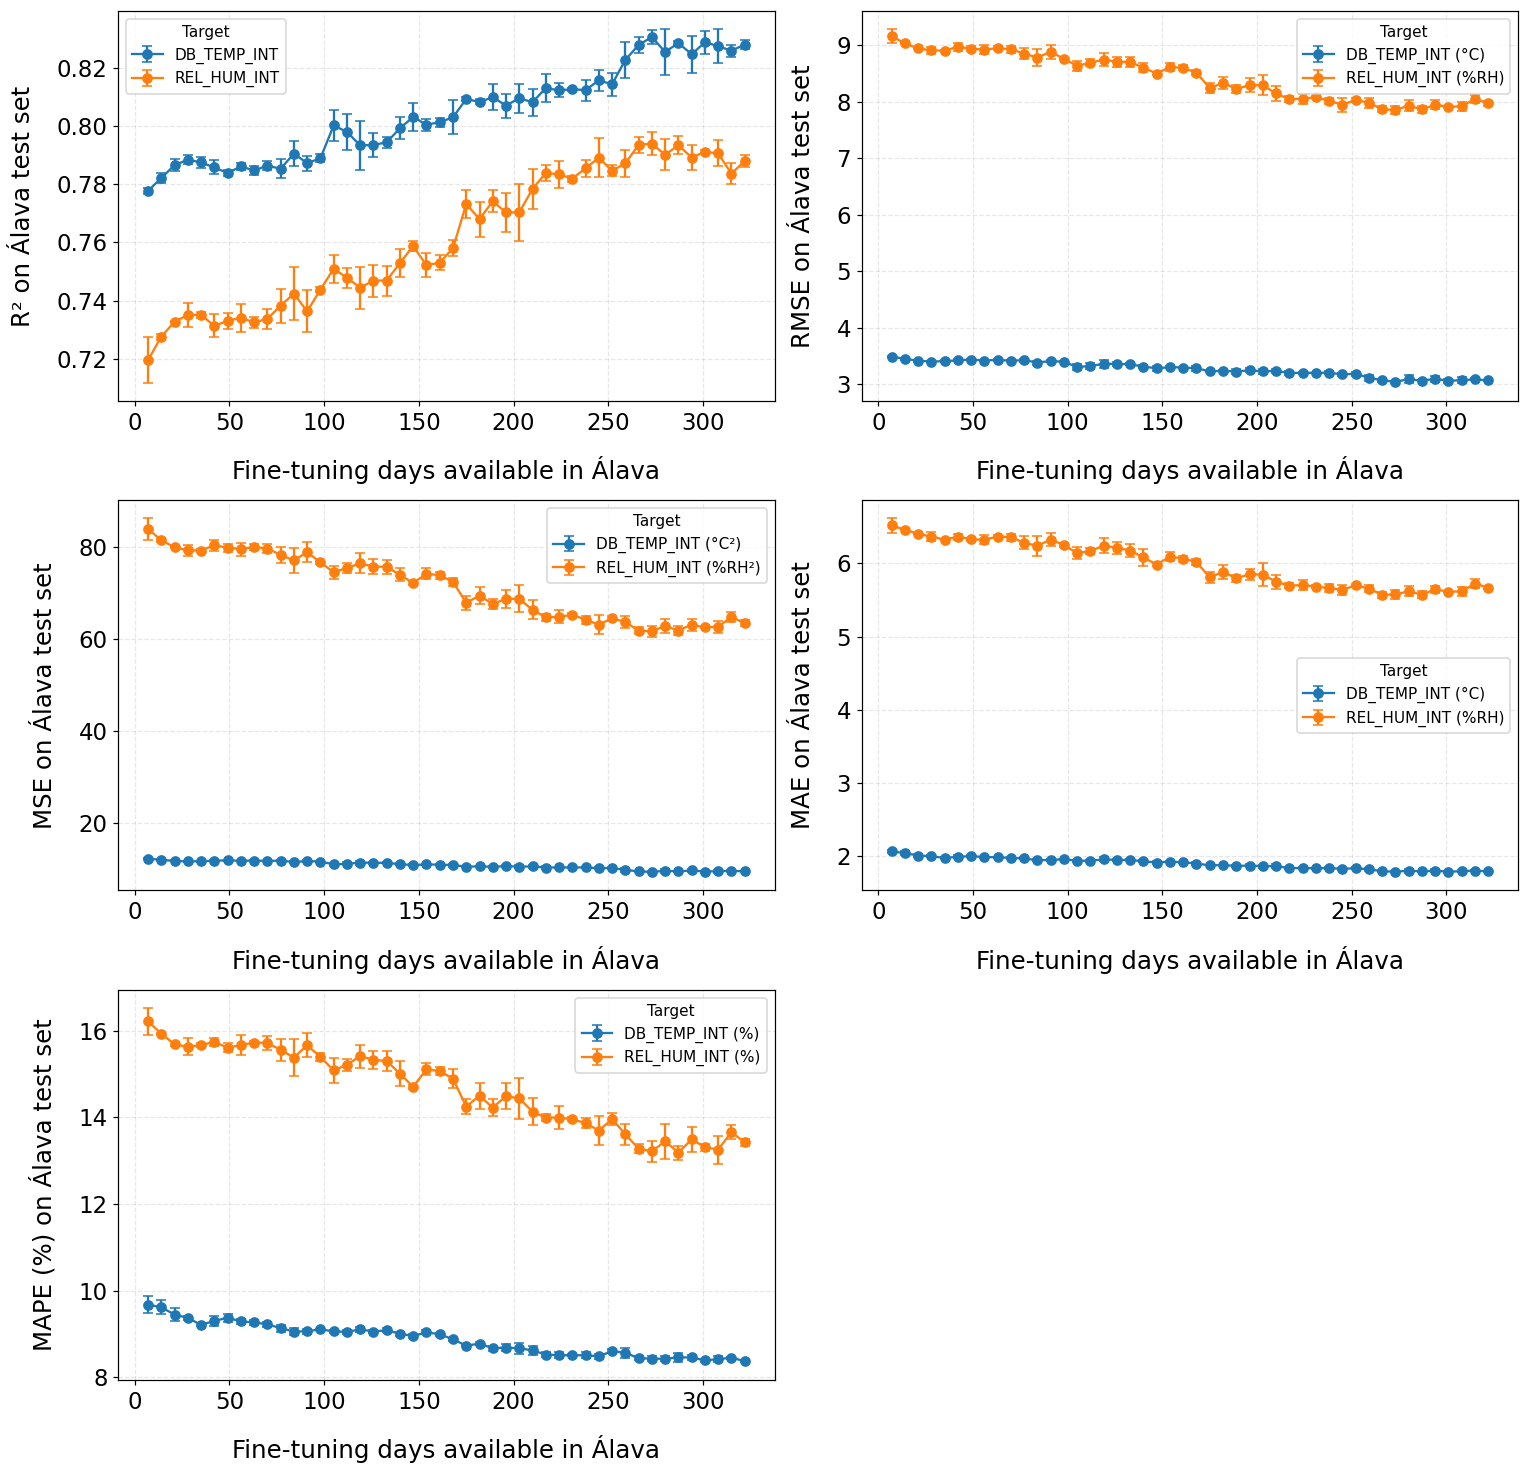

In [8]:
B_METRICS = ["r2", "rmse", "mse", "mae", "mape"]


def target_legend_label(target, metric):
    # Legend label for a target with the unit of the given metric.
    unit = UNITS.get(target, "")
    if metric == "r2" or not unit:
        return target                      # dimensionless
    if metric == "mape":
        return f"{target} (%)"             # already a percentage
    if metric == "mse":
        return f"{target} ({unit}\u00b2)"  # squared unit
    return f"{target} ({unit})"            # rmse, mae


def plot_learning_curve_all_metrics(df_b_agg, targets, metrics=B_METRICS,
                                    ncols=2, figsize=(7, 4.5)):
    """One subplot per metric in a single figure, each showing every target
    against the number of fine-tuning days (mean ± std across seeds)."""
    nrows = -(-len(metrics) // ncols)  # ceil division
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0] * ncols, figsize[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        for target in targets:
            ax.errorbar(
                df_b_agg["finetune_days"],
                df_b_agg[f"{target}_{metric}_mean"],
                yerr=df_b_agg[f"{target}_{metric}_std"].fillna(0),
                marker="o", capsize=3, label=target_legend_label(target, metric),
            )
        apply_style(ax, title=f"Learning curve: {METRIC_LABELS[metric]} vs fine-tuning days",
                    xlabel=f"Fine-tuning days available in {destination_label}",
                    ylabel=f"{METRIC_LABELS[metric]} on {destination_label} test set",
                    legend_title="Target")

    # Hide unused axes if metrics don't fill the grid exactly
    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig


plot_learning_curve_all_metrics(df_b_agg, targets_b)
plt.show()

## 6. Experiment C - Same greenhouse vs zero-shot transfer vs fine-tuning

Compares three ways of obtaining a model for the destination greenhouse:

1. **Same greenhouse**: trained and evaluated directly on the destination.
2. **Zero-shot transfer**: model trained only on the source greenhouse, evaluated on the
   destination WITHOUT any fine-tuning.
3. **Fine-tuning**: the same source model, fine-tuned on destination data.

The JSON files of each target are read from `TARGET_DIRS`. The condition is inferred from
the file name: files containing `zeroshot` are zero-shot transfer, files containing
`finetuned` are fine-tuning, and any other file is assumed to be same greenhouse. If a
same-greenhouse file name collides with this rule, add it to `MANUAL_CONDITIONS`.

In [9]:
PATTERN = "*.json"

COND_ZEROSHOT = "Zero-shot transfer"
COND_FINETUNED = "Fine-tuning"
COND_SAME = "Same greenhouse"

# Narrative order of the conditions in the plots (from expected "worst" to "best").
# Any condition not in this list is appended at the end.
CONDITION_ORDER = [COND_ZEROSHOT, COND_FINETUNED, COND_SAME]

# Manual overrides: file name (without extension) -> condition.
MANUAL_CONDITIONS = {
    # "some_same_greenhouse_file": COND_SAME,
}


def infer_condition(experiment_name):
    if experiment_name in MANUAL_CONDITIONS:
        return MANUAL_CONDITIONS[experiment_name]
    n = experiment_name.lower()
    if "finetuned" in n or "finetuning" in n:
        return COND_FINETUNED
    if "zeroshot" in n or "zero_shot" in n:
        return COND_ZEROSHOT
    return COND_SAME


def category_order(values):
    present = list(dict.fromkeys(values))  # unique values, keeps order of appearance
    return [c for c in CONDITION_ORDER if c in present] + [c for c in present if c not in CONDITION_ORDER]

### Load the JSON files

In [10]:
def load_results(directory: Path, target_variable: str, pattern: str = "*.json"):
    files = sorted(Path(directory).glob(pattern))
    data = []
    for f in files:
        with open(f, "r", encoding="utf-8") as fh:
            content = json.load(fh)
        items = content if isinstance(content, list) else [content]
        for i, d in enumerate(items):
            d = dict(d)
            d["_file"] = f.name if len(items) == 1 else f"{f.name}[{i}]"
            d["_experiment"] = f.stem
            d["_condition"] = infer_condition(f.stem)
            d["_target_variable"] = d.get("target_variable", target_variable)
            data.append(d)
    return data


data = []
for target_variable, directory in TARGET_DIRS.items():
    if not directory.exists():
        print(f"Warning: directory '{directory}' does not exist, skipping.")
        continue
    data += load_results(directory, target_variable, PATTERN)

print(f"Loaded {len(data)} result entries.")
print()
print("Detected experiments -> assigned condition:")
seen = set()
for d in data:
    key = (d["_target_variable"], d["_experiment"])
    if key in seen:
        continue
    seen.add(key)
    print(f"  [{d['_target_variable']:<14}] {d['_experiment']:<45} -> {d['_condition']}")

Loaded 18 result entries.

Detected experiments -> assigned condition:
  [DB_TEMP_INT   ] 04_itransformer_cartagena_alava_direct_comparison_finetuned -> Fine-tuning
  [DB_TEMP_INT   ] 04_itransformer_cartagena_alava_direct_comparison_reference -> Same greenhouse
  [DB_TEMP_INT   ] 04_itransformer_cartagena_alava_direct_comparison_zeroshot -> Zero-shot transfer
  [REL_HUM_INT   ] 04_itransformer_cartagena_alava_direct_comparison_finetuned -> Fine-tuning
  [REL_HUM_INT   ] 04_itransformer_cartagena_alava_direct_comparison_reference -> Same greenhouse
  [REL_HUM_INT   ] 04_itransformer_cartagena_alava_direct_comparison_zeroshot -> Zero-shot transfer


### Build the DataFrames

In [11]:
def build_global_df(data):
    rows = []
    for d in data:
        row = {"target_variable": d["_target_variable"], "condition": d["_condition"],
               "experiment": d["_experiment"], "file": d["_file"]}
        row.update(d["metrics"]["global"])
        rows.append(row)
    return pd.DataFrame(rows)


def build_horizon_df(data):
    rows = []
    for d in data:
        for h_key, metrics in d["metrics"].get("per_horizon", {}).items():
            row = {"target_variable": d["_target_variable"], "condition": d["_condition"],
                   "experiment": d["_experiment"], "file": d["_file"],
                   "horizon": int(h_key.split("_")[1])}
            row.update(metrics)
            rows.append(row)
    return pd.DataFrame(rows)


df_global = build_global_df(data)
df_horizon = build_horizon_df(data)
targets = sorted(df_global["target_variable"].unique())
df_global.head()

,target_variable,condition,experiment,file,r2,mse,rmse,mae,mape,relative_error,relative_error_abs
0,DB_TEMP_INT,Fine-tuning,04_itransformer_cartagena_alava_direct_compari...,04_itransformer_cartagena_alava_direct_compari...,0.828,9.376,3.062,1.784,8.349,-0.004,0.083
1,DB_TEMP_INT,Fine-tuning,04_itransformer_cartagena_alava_direct_compari...,04_itransformer_cartagena_alava_direct_compari...,0.814,10.137,3.184,1.883,8.686,-0.008,0.087
2,DB_TEMP_INT,Fine-tuning,04_itransformer_cartagena_alava_direct_compari...,04_itransformer_cartagena_alava_direct_compari...,0.824,9.592,3.097,1.823,8.612,0.005,0.086
3,DB_TEMP_INT,Same greenhouse,04_itransformer_cartagena_alava_direct_compari...,04_itransformer_cartagena_alava_direct_compari...,0.877,6.707,2.590,1.679,8.455,0.003,0.085
4,DB_TEMP_INT,Same greenhouse,04_itransformer_cartagena_alava_direct_compari...,04_itransformer_cartagena_alava_direct_compari...,0.888,6.097,2.469,1.628,8.368,0.009,0.084


### C.1 - Comparison table (mean ± std per target variable x condition)

In [12]:
def mean_std_table(df, metrics, group_cols):
    agg = df.groupby(group_cols)[metrics].agg(["mean", "std"])
    out = pd.DataFrame(index=agg.index)
    for m in metrics:
        mean = agg[(m, "mean")]
        std = agg[(m, "std")].fillna(0)
        out[m] = [f"{mu:.3f} \u00b1 {sd:.3f}" for mu, sd in zip(mean, std)]
    return out


comparison_table = mean_std_table(df_global, METRICS, ["target_variable", "condition"])
comparison_table = comparison_table.reindex(
    pd.MultiIndex.from_product([
        sorted(df_global["target_variable"].unique()),
        category_order(df_global["condition"]),
    ], names=["target_variable", "condition"])
).dropna(how="all")
comparison_table

r2             mse  \
target_variable condition                                           
DB_TEMP_INT     Zero-shot transfer  0.766 ± 0.005  12.769 ± 0.299   
                Fine-tuning         0.822 ± 0.007   9.702 ± 0.392   
                Same greenhouse     0.882 ± 0.006   6.438 ± 0.311   
REL_HUM_INT     Zero-shot transfer  0.671 ± 0.018  98.475 ± 5.282   
                Fine-tuning         0.789 ± 0.003  63.273 ± 0.793   
                Same greenhouse     0.801 ± 0.001  59.510 ± 0.238   

                                             rmse            mae  \
target_variable condition                                          
DB_TEMP_INT     Zero-shot transfer  3.573 ± 0.042  2.142 ± 0.024   
                Fine-tuning         3.114 ± 0.063  1.830 ± 0.050   
                Same greenhouse     2.537 ± 0.062  1.652 ± 0.026   
REL_HUM_INT     Zero-shot transfer  9.921 ± 0.268  7.284 ± 0.217   
                Fine-tuning         7.954 ± 0.050  5.659 ± 0.070   
                Same greenhouse     7.714 ± 0.015  5.495 ± 0.015   

                                              mape  
target_variable condition                           
DB_TEMP_INT     Zero-shot transfer  10.066 ± 0.115  
                Fine-tuning          8.549 ± 0.177  
                Same greenhouse      8.382 ± 0.067  
REL_HUM_INT     Zero-shot transfer  17.808 ± 0.409  
                Fine-tuning         13.222 ± 0.131  
                Same greenhouse     12.044 ± 0.154

### C.2 - Improvement of fine-tuning over zero-shot transfer

Positive = fine-tuning improves over zero-shot transfer. For `r2` the improvement is the
difference in points (not a %, because it can cross 0); for the other metrics (where lower is
better) it is the % reduction of the error.

In [13]:
improvement_rows = []
for target in targets:
    row = {"target_variable": target}
    for metric in METRICS:
        zs = df_global[(df_global.target_variable == target) & (df_global.condition == COND_ZEROSHOT)][metric].mean()
        ft = df_global[(df_global.target_variable == target) & (df_global.condition == COND_FINETUNED)][metric].mean()
        if pd.isna(zs) or pd.isna(ft):
            continue
        if metric == "r2":
            row[f"improvement_{metric}_pp"] = ft - zs
        else:
            row[f"improvement_{metric}_pct"] = 100 * (zs - ft) / zs
    improvement_rows.append(row)

pd.DataFrame(improvement_rows).set_index("target_variable")

,improvement_r2_pp,improvement_mse_pct,improvement_rmse_pct,improvement_mae_pct,improvement_mape_pct
target_variable,,,,,
DB_TEMP_INT,0.056,24.020,12.841,14.548,15.075
REL_HUM_INT,0.118,35.747,19.824,22.304,25.751


### C.3 - Evolution per prediction horizon, per condition

`plot_metric_per_horizon()` draws one metric for one target, with one line per condition
(mean ± std across repetitions).

In [14]:
def plot_metric_per_horizon(df_horizon, target, metric="r2", ax=None, title=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=FIGSIZE)

    sub_target = df_horizon[df_horizon["target_variable"] == target]
    for cond in category_order(sub_target["condition"]):
        sub = sub_target[sub_target["condition"] == cond]
        agg = sub.groupby("horizon")[metric].agg(["mean", "std"]).sort_index()
        ax.plot(agg.index, agg["mean"], marker="o", markersize=3, label=cond)
        std = agg["std"].fillna(0)
        if (std > 0).any():
            ax.fill_between(agg.index, agg["mean"] - std, agg["mean"] + std, alpha=0.15)

    apply_style(ax, title=title or f"{target}: {metric.upper()} evolution per horizon",
                xlabel="Prediction horizon (15-min steps)",
                ylabel=metric_axis_label(metric, target),
                legend_title="Condition")
    return ax

#### Metric chosen in `METRIC`

In [15]:
# for target in targets:
#     fig, ax = plt.subplots(figsize=FIGSIZE)
#     plot_metric_per_horizon(df_horizon, target, metric=METRIC, ax=ax)
#     fig.tight_layout()
#     plt.show()

#### All metrics per horizon (one figure per target: first image temperature and second relative humidity)

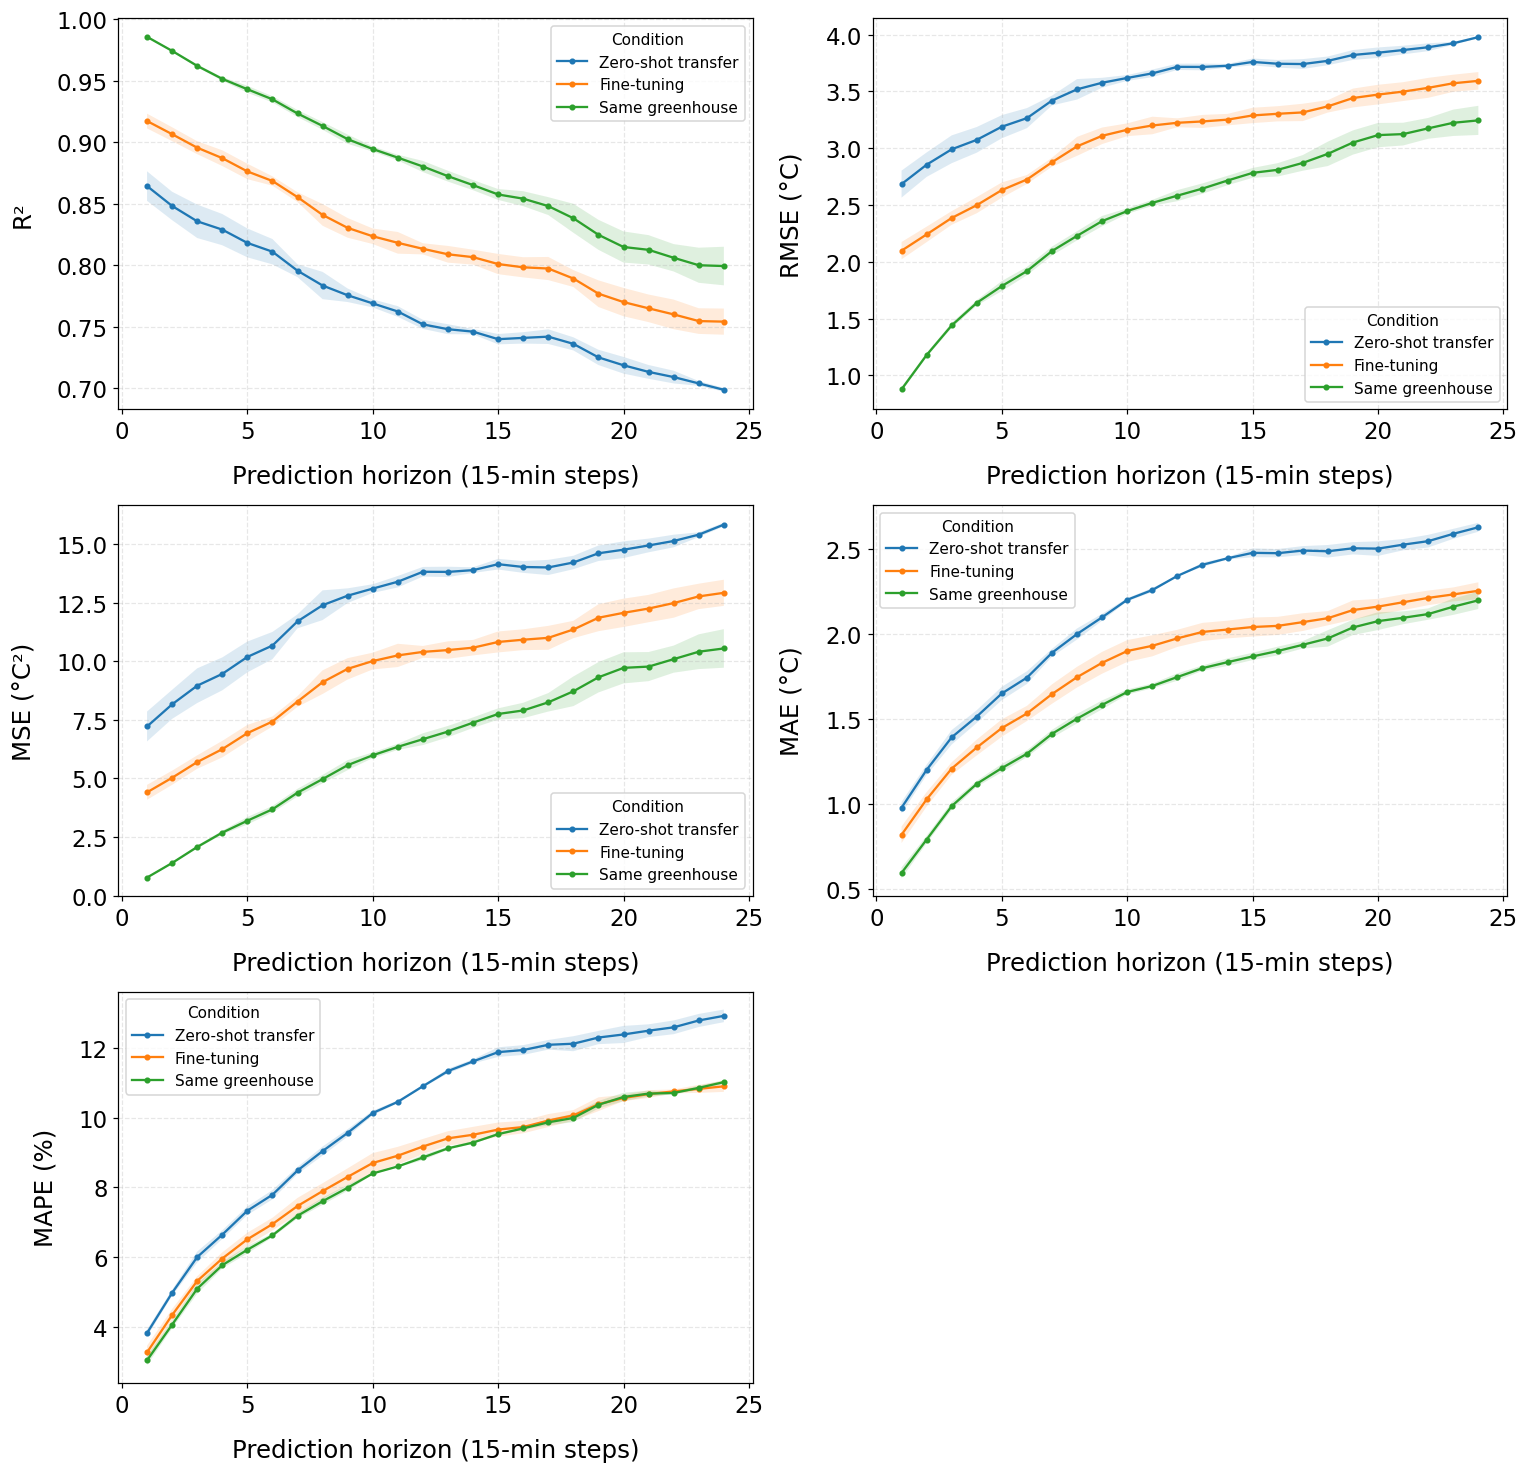

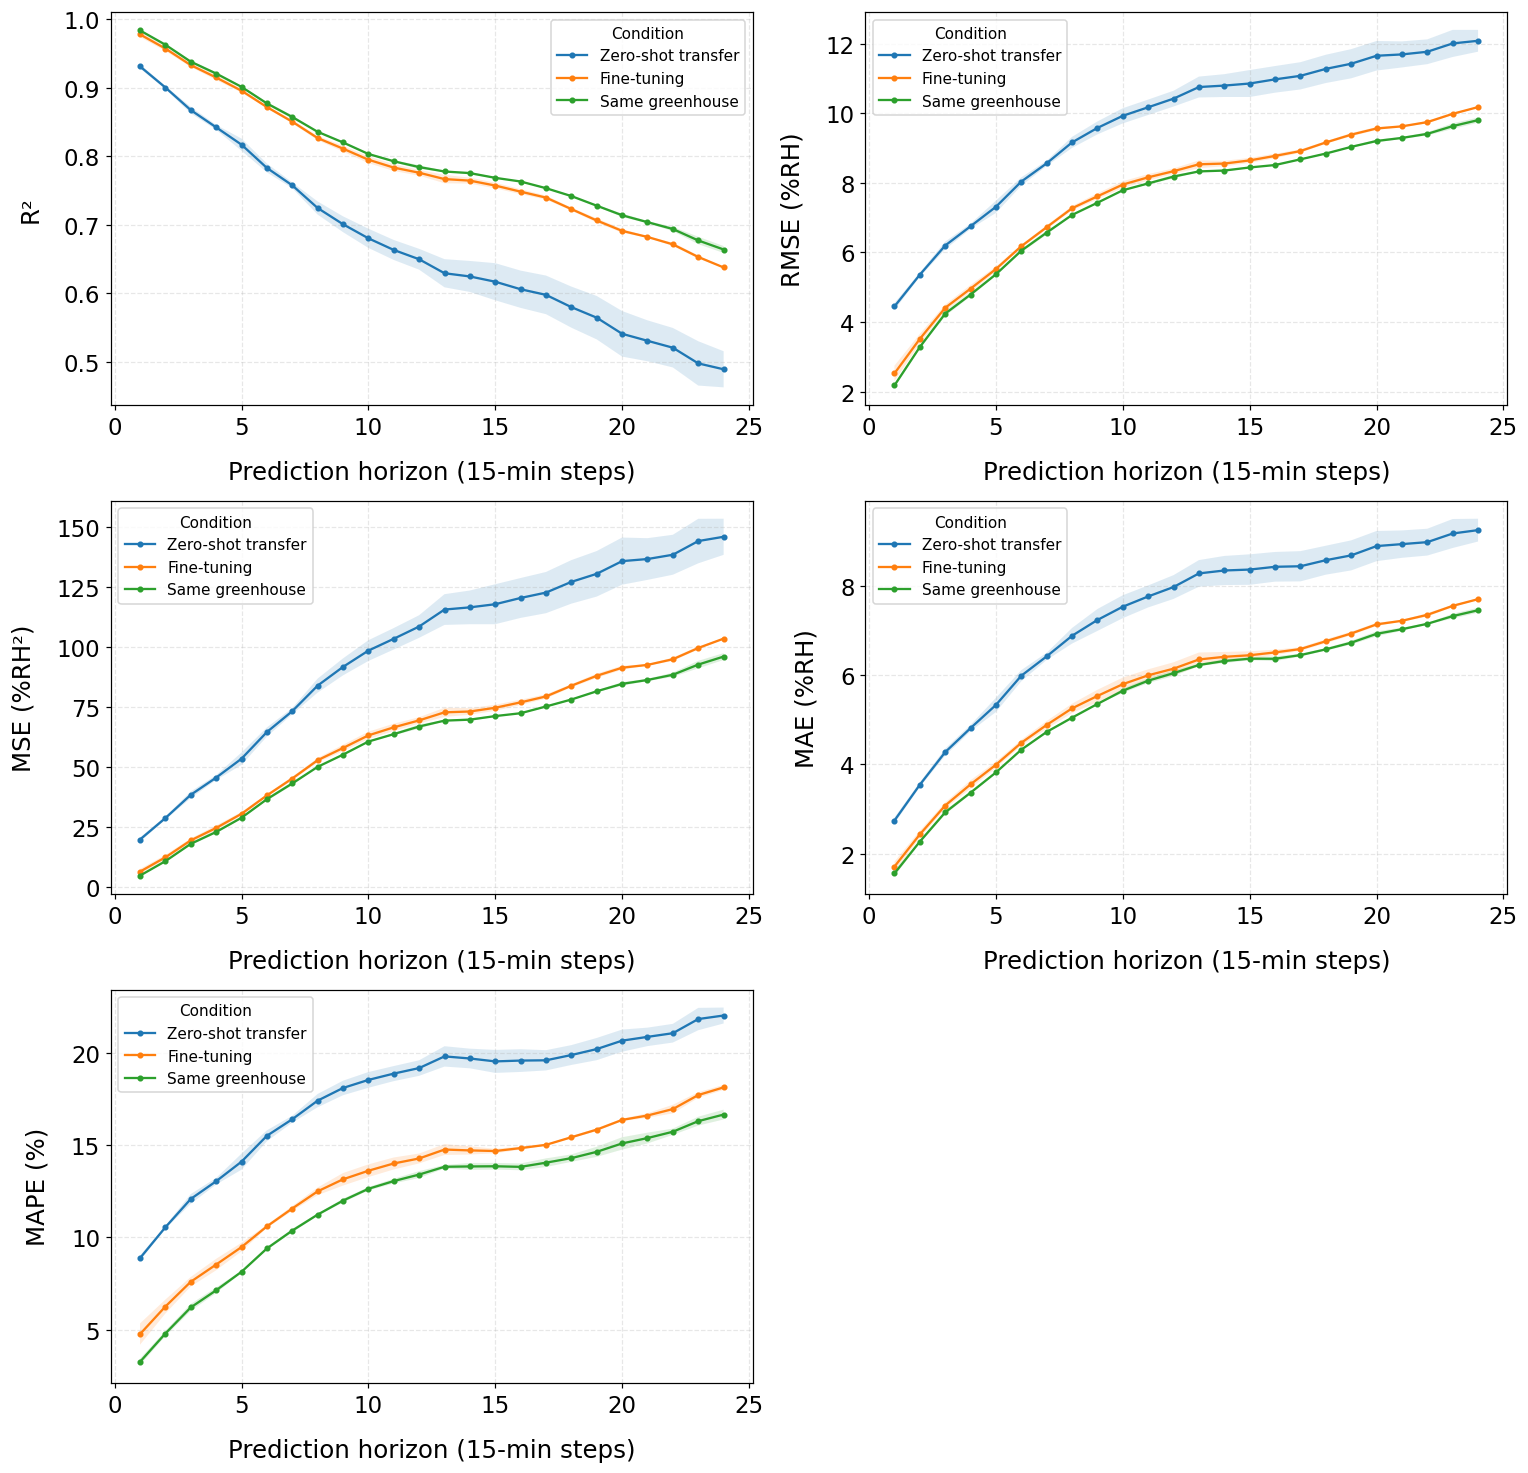

In [16]:
HORIZON_METRICS = ["r2", "rmse", "mse", "mae", "mape"]


def plot_all_metrics_per_horizon(df_horizon, target, metrics=HORIZON_METRICS,
                                 ncols=2, figsize=(7, 4.5)):
    """Draws one subplot per metric for a single target, each showing every
    condition, in a single figure."""
    nrows = -(-len(metrics) // ncols)  # ceil division
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize[0] * ncols, figsize[1] * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, metric in zip(axes, metrics):
        plot_metric_per_horizon(df_horizon, target, metric=metric, ax=ax)

    # Hide unused axes if metrics don't fill the grid exactly
    for ax in axes[len(metrics):]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig


for target in targets:
    plot_all_metrics_per_horizon(df_horizon, target)
    plt.show()